                Q      J_1S(1)      J_Total
0    0.000000e+00 8.488264e-01 8.488264e-01
1    5.000000e-02 8.424919e-01 8.424919e-01
2    1.000000e-01 8.238625e-01 8.238625e-01
3    1.500000e-01 7.940154e-01 7.940154e-01
4    2.000000e-01 7.546035e-01 7.546035e-01
5    2.500000e-01 7.076721e-01 7.076721e-01
6    3.000000e-01 6.554497e-01 6.554497e-01
7    3.500000e-01 6.001500e-01 6.001500e-01
8    4.000000e-01 5.438071e-01 5.438071e-01
9    4.500000e-01 4.881616e-01 4.881616e-01
10   5.000000e-01 4.345991e-01 4.345991e-01
11   5.500000e-01 3.841366e-01 3.841366e-01
12   6.000000e-01 3.374443e-01 3.374443e-01
13   6.500000e-01 2.948914e-01 2.948914e-01
14   7.000000e-01 2.566020e-01 2.566020e-01
15   7.500000e-01 2.225147e-01 2.225147e-01
16   8.000000e-01 1.924364e-01 1.924364e-01
17   8.500000e-01 1.660891e-01 1.660891e-01
18   9.000000e-01 1.431473e-01 1.431473e-01
19   9.500000e-01 1.232664e-01 1.232664e-01
20   1.000000e+00 1.061033e-01 1.061033e-01
21   1.050000e+00 9.132945e-02 9

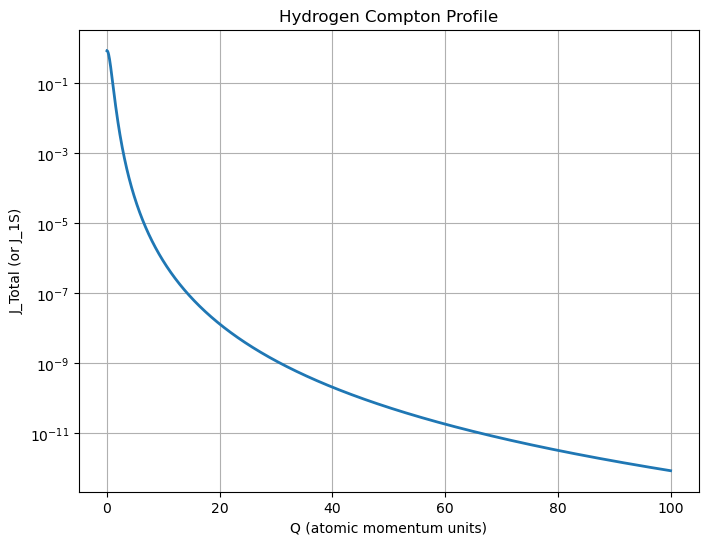

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================
# Hydrogen 1s Compton Profile
# J(Q) = 8 / [3*pi*(1+Q^2)^3]
# Q in atomic momentum units
# ==========================================

def J(Q):
    return 8.0 / (3.0 * np.pi * (1.0 + Q**2)**3)
# ==========================================
# Generate Q values
# step = 0.05
# up to Q = 100
# ==========================================

Q_values = np.arange(0.0, 100.0 + 0.05, 0.05)
# Calculate J(Q)
J_values = J(Q_values)
# ==========================================
# Create Table
# ==========================================

table = pd.DataFrame({
    "Q": Q_values,
    "J_1S(1)": J_values,
    "J_Total": J_values 
})

# ==========================================
# Print Table
# ==========================================

pd.set_option("display.max_rows", None)
pd.set_option("display.float_format", "{:.6e}".format)

print(table)

# ==========================================
# Save table to CSV
# ==========================================

table.to_csv("Hydrogen_Compton_Profile.csv", index=False)

print("\nTable saved as Hydrogen_Compton_Profile.csv")

# ==========================================
# Plot
# ==========================================

plt.figure(figsize=(8,6))

plt.plot(Q_values, J_values, linewidth=2)

plt.xlabel("Q (atomic momentum units)")
plt.ylabel("J_Total (or J_1S)")
plt.title("Hydrogen Compton Profile")

plt.yscale("log")   # useful because J(Q) drops rapidly

plt.grid(True)

plt.show()

                Q           J(Q)        sigma_Q  Absolute_Uncertainty  \
0  0.00000000e+00 8.48826363e-01 1.00000000e-02        0.00000000e+00   
1  5.00000000e-02 8.42491864e-01 1.00000000e-02        2.52117266e-03   
2  1.00000000e-01 8.23862505e-01 1.00000000e-02        4.89423271e-03   
3  1.50000000e-01 7.94015370e-01 1.00000000e-02        6.98888835e-03   
4  2.00000000e-01 7.54603546e-01 1.00000000e-02        8.70696399e-03   
5  2.50000000e-01 7.07672050e-01 1.00000000e-02        9.99066424e-03   
6  3.00000000e-01 6.55449695e-01 1.00000000e-02        1.08239399e-02   
7  3.50000000e-01 6.00150000e-01 1.00000000e-02        1.12277506e-02   
8  4.00000000e-01 5.43807123e-01 1.00000000e-02        1.12511819e-02   
9  4.50000000e-01 4.88161590e-01 1.00000000e-02        1.09608008e-02   
10 5.00000000e-01 4.34599098e-01 1.00000000e-02        1.04303784e-02   
11 5.50000000e-01 3.84136578e-01 1.00000000e-02        9.73244306e-03   
12 6.00000000e-01 3.37444329e-01 1.00000000e-02    

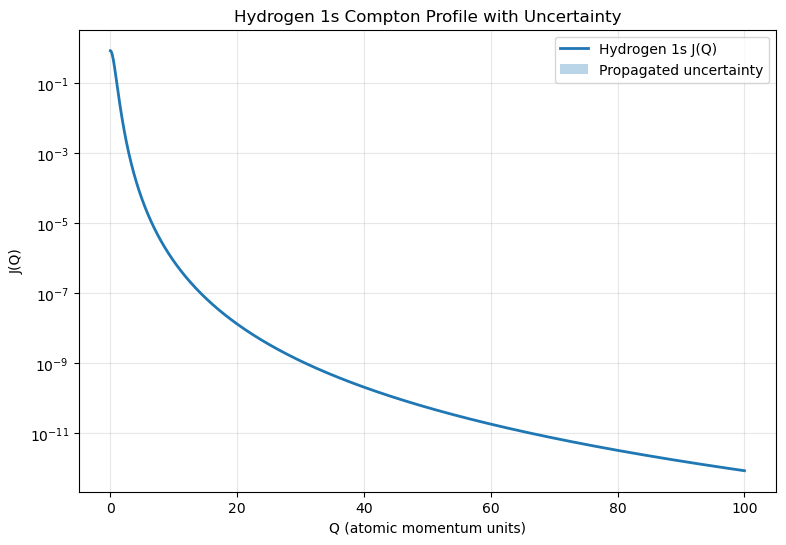

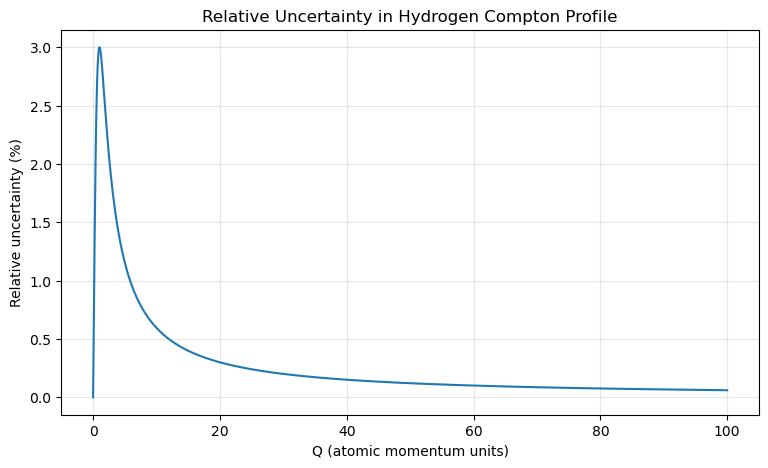

In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================
# Hydrogen 1s Compton Profile
# ==========================================

def J(Q):
    return 8.0 / (3.0 * np.pi * (1.0 + Q**2)**3)

# Derivative of J(Q)
def dJ_dQ(Q):
    return -16.0 * Q / (np.pi * (1.0 + Q**2)**4)

# ==========================================
# Momentum values
# ==========================================

Q_values = np.arange(0.0, 100.0 + 0.025, 0.05)

# Assumed standard uncertainty in Q
sigma_Q = 0.01  # atomic units (example only)

# Calculate Compton profile
J_values = J(Q_values)

# Absolute propagated uncertainty
sigma_J = np.abs(dJ_dQ(Q_values)) * sigma_Q

# Relative uncertainty (%)
relative_uncertainty = (
    sigma_J / J_values
) * 100

# ==========================================
# Create table
# ==========================================

table = pd.DataFrame({
    "Q": Q_values,
    "J(Q)": J_values,
    "sigma_Q": sigma_Q,
    "Absolute_Uncertainty": sigma_J,
    "Relative_Uncertainty_%": relative_uncertainty,
    "J_Lower": J_values - sigma_J,
    "J_Upper": J_values + sigma_J
})

pd.set_option("display.float_format", "{:.8e}".format)

print(table.head(20))

# Save all values
table.to_csv(
    "Hydrogen_uncertainty_Compton_Profile_Uncertainty.csv",
    index=False
)

print("CSV file saved.")

# ==========================================
# Plot Compton Profile with uncertainty
# ==========================================

plt.figure(figsize=(9, 6))

plt.plot(
    Q_values, J_values,
    label="Hydrogen 1s J(Q)",
    linewidth=2
)

plt.fill_between(
    Q_values,
    np.maximum(J_values - sigma_J, 1e-30),
    J_values + sigma_J,
    alpha=0.3,
    label="Propagated uncertainty"
)

plt.xlabel("Q (atomic momentum units)")
plt.ylabel("J(Q)")
plt.title("Hydrogen 1s Compton Profile with Uncertainty")
plt.yscale("log")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

# ==========================================
# Plot relative uncertainty
# ==========================================

plt.figure(figsize=(9, 5))

plt.plot(Q_values, relative_uncertainty)

plt.xlabel("Q (atomic momentum units)")
plt.ylabel("Relative uncertainty (%)")
plt.title("Relative Uncertainty in Hydrogen Compton Profile")
plt.grid(True, alpha=0.3)
plt.show()
